# Per-module space charge (gain × IBF) inside one RHIC fill (2026-10-23)
**Idea.** Inside one fill the static is the same, so differences between runs of the fill (79508 at 2.7 µA → 79516 at 1.9 µA)
measure only the space charge. The field is linear in the charge, so instead of scanning gain settings: one field map per pad
module (12 sectors × R1 / R2 / R3 × 2 sides = 72 Rossegger solutions of the final density map with only that module's charge;
their sum with the charge fractions reproduces the full map to < 10⁻⁴), and one CM correction per module and block (v12,
8 blocks of 79508 / 79513 / 79516). Then the module weights g are fitted: static-only data = common static + Σ_m g_m ×
(module m's correction).

**Observable**: dφ per (30° sector, R bin) on a fixed cluster set per block (every configuration on the same raw clusters),
built linearly from per-cluster corrections, R > 34 cm.

**Status**: the basis works (closure 1–2 %), but the fitted g do not predict a run left out of the fit: runs of the same fill
differ by 0.1–0.2 mrad per bin, 3–5× the block-to-block noise, more than the gain effect at this lever. Sections 1–3 show
the data and the fits; Section 4 the tracks.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '/home/yoren/bnl/ROOT/install/lib')
import numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
import truthalign as ta, gainstudy as gs, gfit
plt.rcParams['figure.dpi'] = 72
ta.correct_truth()
def show(*figs):
    for f in figs:
        display(f)
    plt.close('all')

## 1. The data inside the fill
### 1a. Noise: adjacent blocks of one run vs first and last block

In [2]:
gs.noise_table()

Welcome to JupyROOT 6.30/06


South 79513: per-bin noise per block (rms of block difference / sqrt 2): b0 - b1000: 0.047 | b1000 - b2000: 0.048 | b0 - b2000: 0.079


South 79516: per-bin noise per block (rms of block difference / sqrt 2): b0 - b1000: 0.042 | b1000 - b2000: 0.047 | b0 - b2000: 0.059


South 79508: per-bin noise per block (rms of block difference / sqrt 2): b0 - b1000: 0.111


North 79513: per-bin noise per block (rms of block difference / sqrt 2): b0 - b1000: 0.054 | b1000 - b2000: 0.048 | b0 - b2000: 0.077


North 79516: per-bin noise per block (rms of block difference / sqrt 2): b0 - b1000: 0.021 | b1000 - b2000: 0.020 | b0 - b2000: 0.033


North 79508: per-bin noise per block (rms of block difference / sqrt 2): b0 - b1000: 0.082


### 1b. Laser cluster properties per block

In [3]:
gs.cluster_stats()

South: block, I [uA], median cluster ADC sum, two-row fraction, matched clusters


   79508 b   0: I 2.74, ADC   1721, two-row 0.483, n 2480
   79508 b1000: I 2.65, ADC   1769, two-row 0.499, n 2476
   79513 b   0: I 2.15, ADC   1832, two-row 0.530, n 2447
   79513 b1000: I 2.11, ADC   1828, two-row 0.536, n 2440
   79513 b2000: I 2.10, ADC   1824, two-row 0.536, n 2438
   79516 b   0: I 1.87, ADC   1848, two-row 0.550, n 2431
   79516 b1000: I 1.84, ADC   1835, two-row 0.552, n 2429
   79516 b2000: I 1.81, ADC   1809, two-row 0.549, n 2422
North: block, I [uA], median cluster ADC sum, two-row fraction, matched clusters
   79508 b   0: I 2.87, ADC   2977, two-row 0.368, n 2361
   79508 b1000: I 2.79, ADC   3013, two-row 0.370, n 2365
   79513 b   0: I 2.26, ADC   3113, two-row 0.383, n 2577
   79513 b1000: I 2.26, ADC   3077, two-row 0.383, n 2577
   79513 b2000: I 2.19, ADC   3083, two-row 0.387, n 2579
   79516 b   0: I 1.95, ADC   2980, two-row 0.393, n 2566
   79516 b1000: I 1.94, ADC   2958, two-row 0.391, n 2564
   79516 b2000: I 1.93, ADC   2966, two-row 0.392

### 1c. 79508 − 79516: measured change, what the final correction removes, what is left, noise (sector × R)

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/gainstudy.py:36: RuntimeWarning: Mean of empty slice
  Y8 = np.nanmean([d['f12_static'] for d in d8], axis=0); Y6 = np.nanmean([d['f12_static'] for d in d6], axis=0)
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/gainstudy.py:37: RuntimeWarning: Mean of empty slice
  F8 = np.nanmean([d['f12_full'] for d in d8], axis=0); F6 = np.nanmean([d['f12_full'] for d in d6], axis=0)


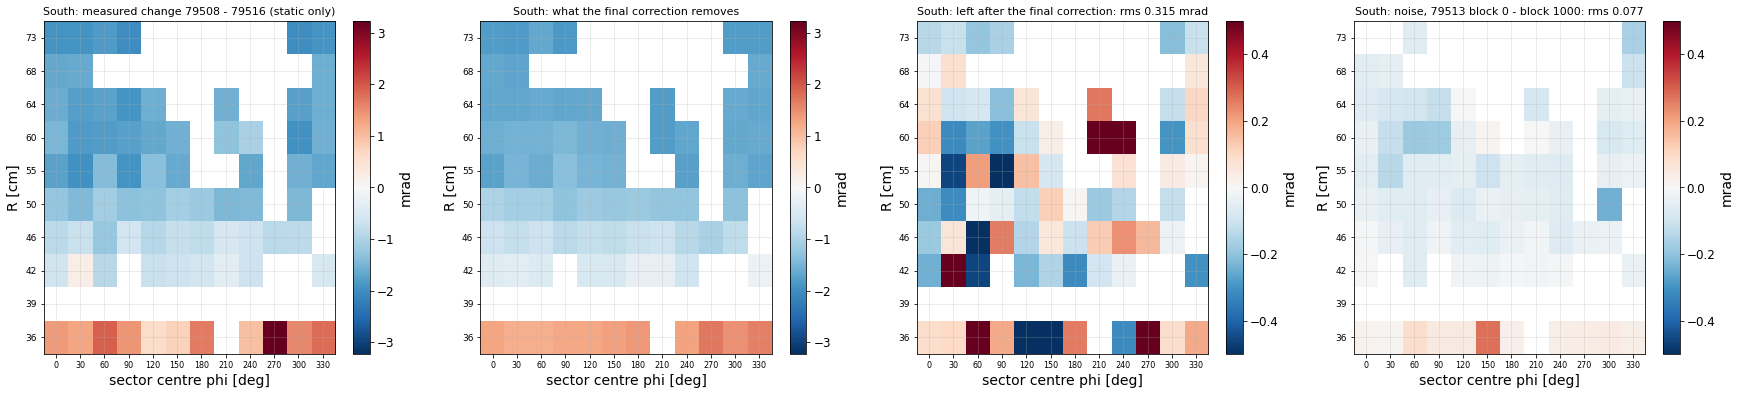

In [4]:
show(gs.fig_fill_change(0))

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/gainstudy.py:36: RuntimeWarning: Mean of empty slice
  Y8 = np.nanmean([d['f12_static'] for d in d8], axis=0); Y6 = np.nanmean([d['f12_static'] for d in d6], axis=0)
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/gainstudy.py:37: RuntimeWarning: Mean of empty slice
  F8 = np.nanmean([d['f12_full'] for d in d8], axis=0); F6 = np.nanmean([d['f12_full'] for d in d6], axis=0)


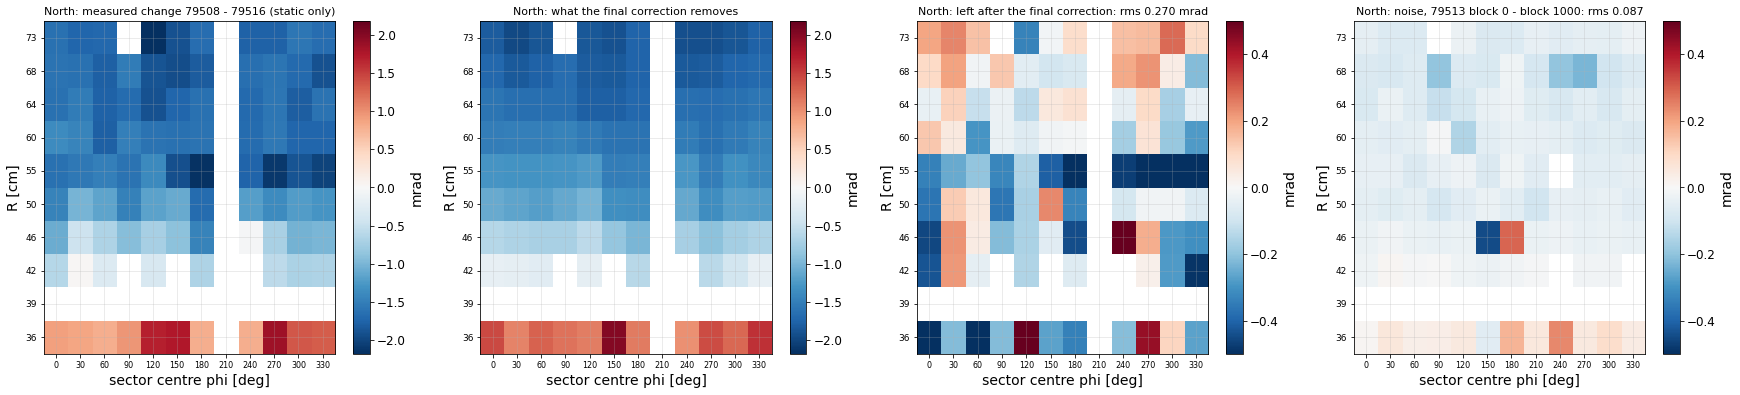

In [5]:
show(gs.fig_fill_change(1))

### 1d. Every block: residual after the final correction minus the fill mean (the run-to-run variation)

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/gainstudy.py:51: RuntimeWarning: Mean of empty slice
  bl = blocks(); R = np.array([gfit.block_bins(r, k, s)['f12_full'] for r, k, I in bl]); ref = np.nanmean(R, axis=0)


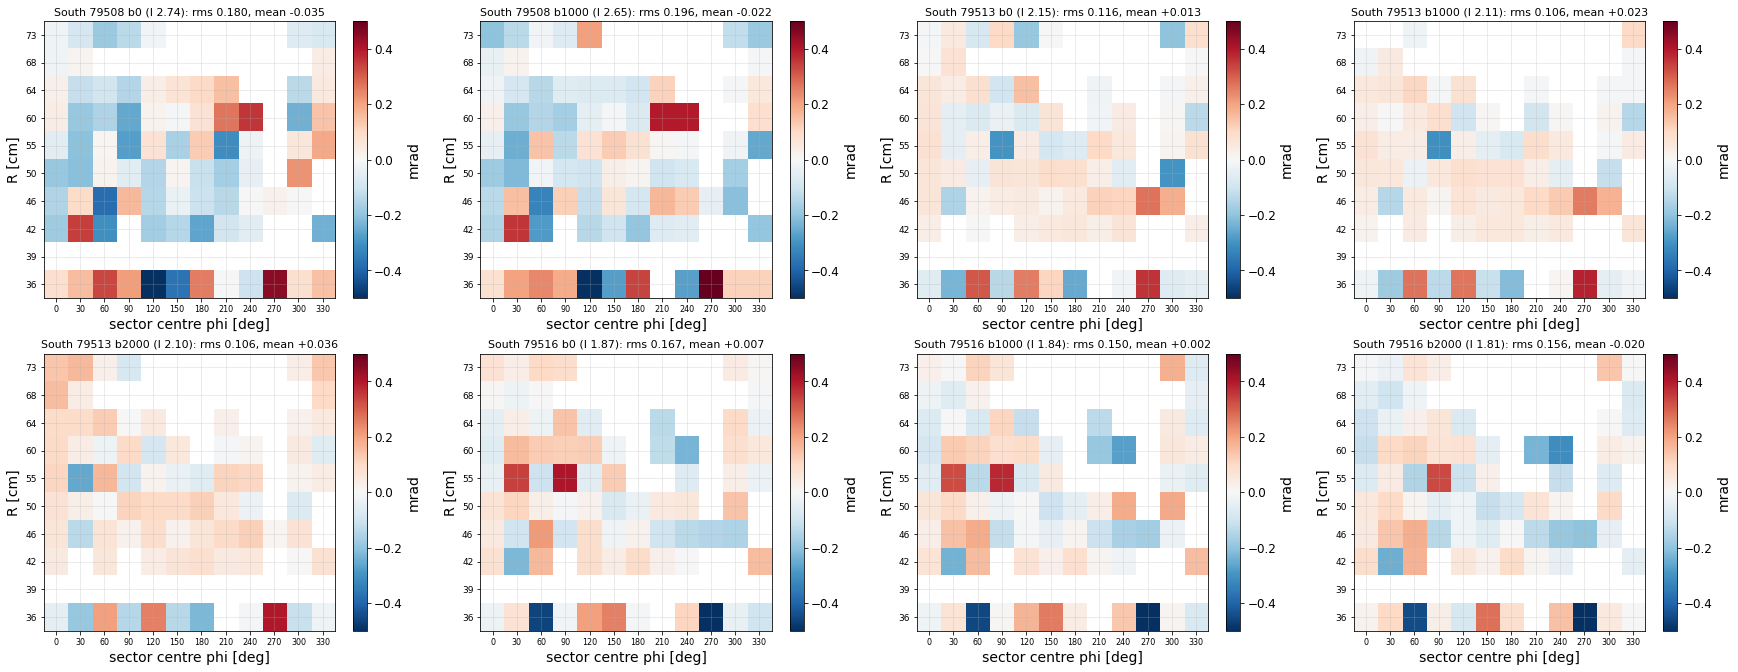

In [6]:
show(gs.fig_block_residuals(0))

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/gainstudy.py:51: RuntimeWarning: Mean of empty slice
  bl = blocks(); R = np.array([gfit.block_bins(r, k, s)['f12_full'] for r, k, I in bl]); ref = np.nanmean(R, axis=0)


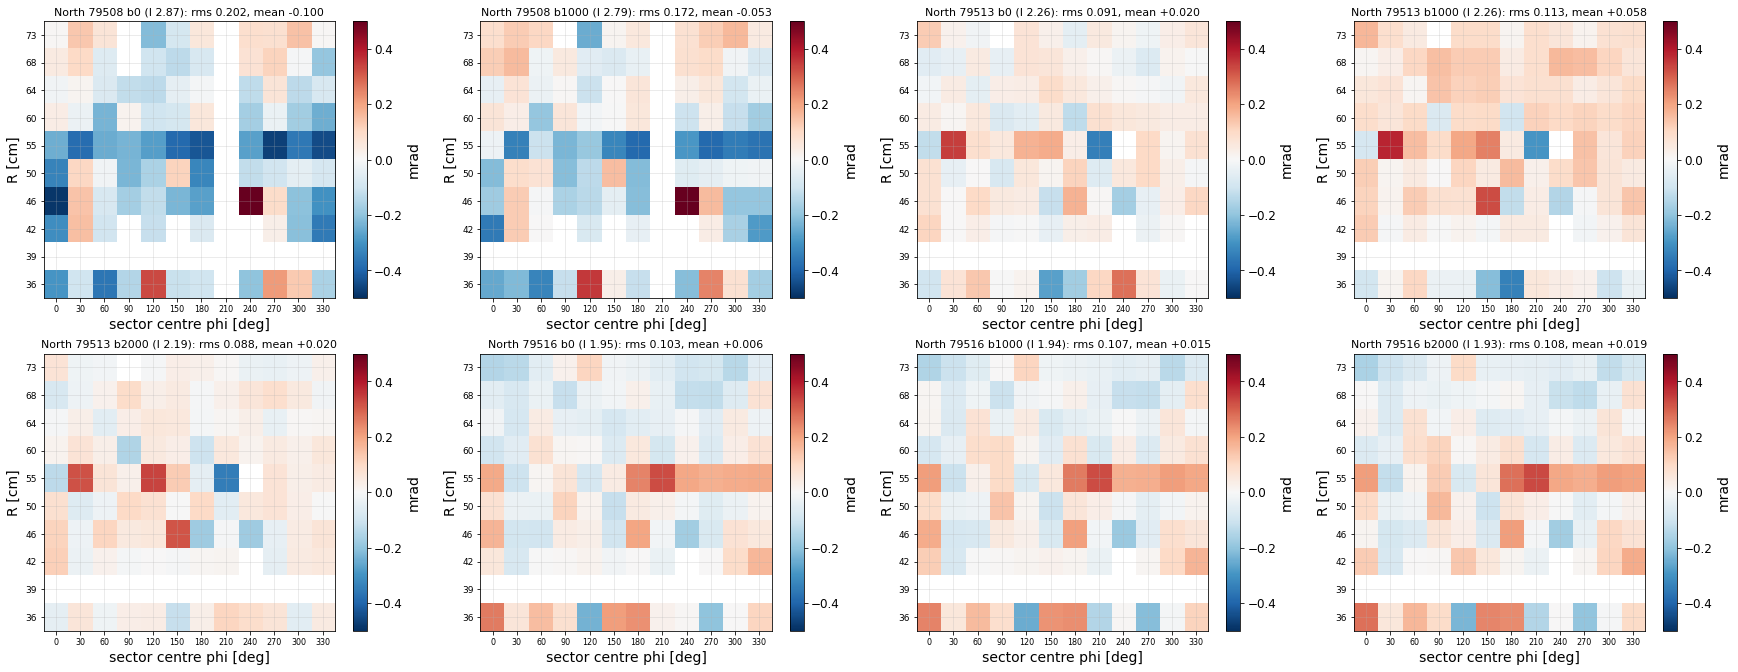

In [7]:
show(gs.fig_block_residuals(1))

- Adjacent blocks of one run agree to 0.02–0.05 mrad per bin; first vs last block of a run 0.06–0.08; whole runs 0.1–0.2:
  a slow variation in time that the current (almost constant inside a run) does not explain.
- 79508 (highest current, earliest) differs most. The two-row fraction of the CM clusters changes with the run (South 0.48 →
  0.55, North 0.37 → 0.39): the stripe images move across pad-row boundaries with the space charge, and one-row clusters
  have a saturated R – the correction is then evaluated at a biased R (Section 3, two-row only).

## 2. The module basis

In [8]:
gs.closure_table()

South 79508 b0: full correction rms 4.57 mrad; sum of the 36 module corrections - full: rms 0.110, max 0.781 mrad
South 79513 b1000: full correction rms 3.46 mrad; sum of the 36 module corrections - full: rms 0.067, max 0.287 mrad
South 79516 b2000: full correction rms 2.98 mrad; sum of the 36 module corrections - full: rms 0.040, max 0.176 mrad
North 79508 b0: full correction rms 4.79 mrad; sum of the 36 module corrections - full: rms 0.059, max 0.267 mrad
North 79513 b1000: full correction rms 3.79 mrad; sum of the 36 module corrections - full: rms 0.054, max 0.223 mrad
North 79516 b2000: full correction rms 3.29 mrad; sum of the 36 module corrections - full: rms 0.060, max 0.485 mrad


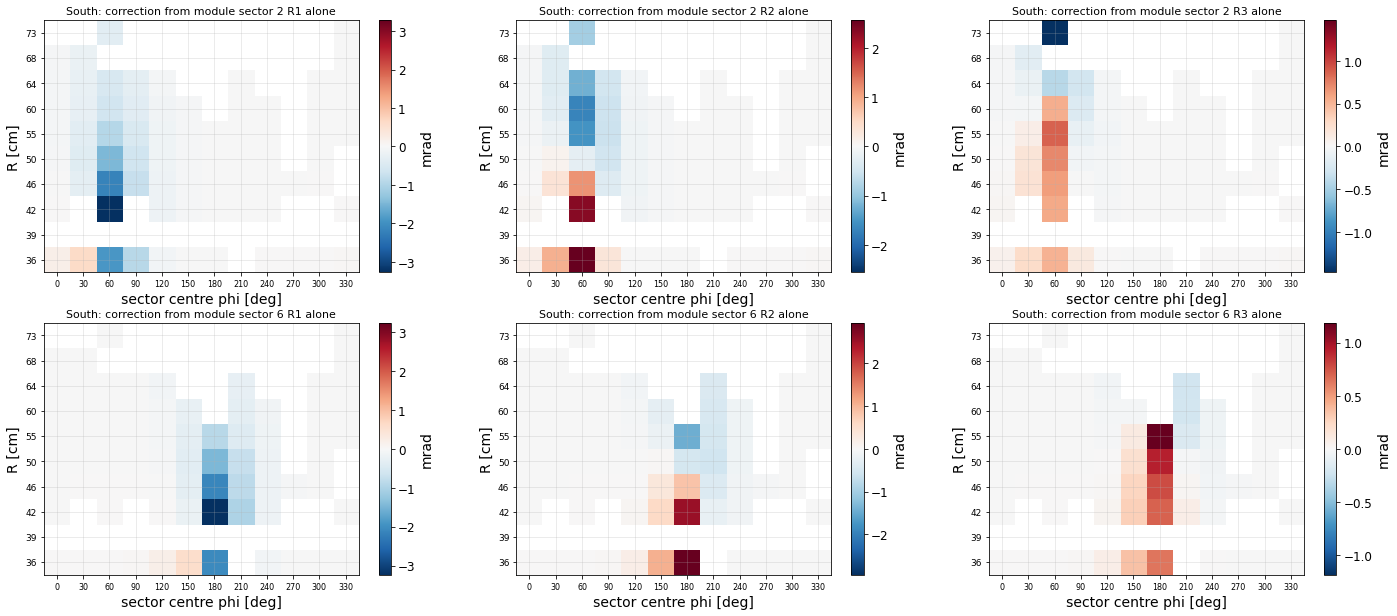

In [9]:
show(gs.fig_module_basis(0))

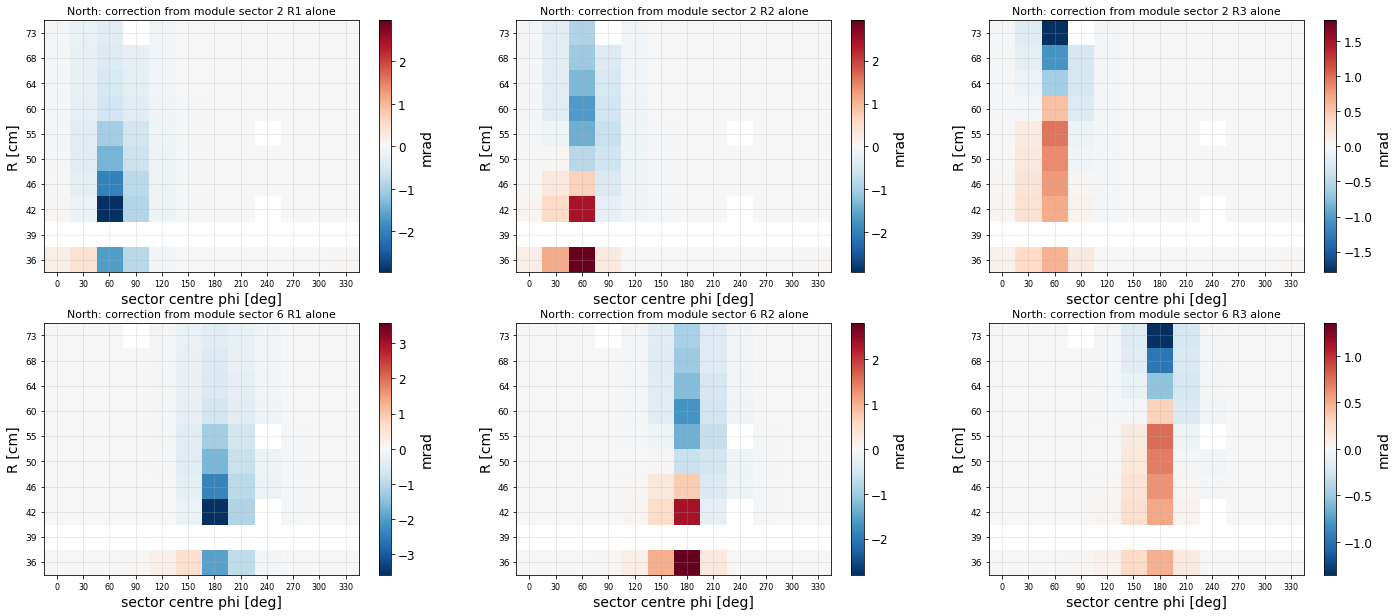

In [10]:
show(gs.fig_module_basis(1))

## 3. Fits
### 3a. The simplest estimate: module change / ring-mean change, independent block pairs, and cross fill

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/fixedset.py:128: RuntimeWarning: Mean of empty slice
  return np.nanmean(G, axis=0), np.array(M)


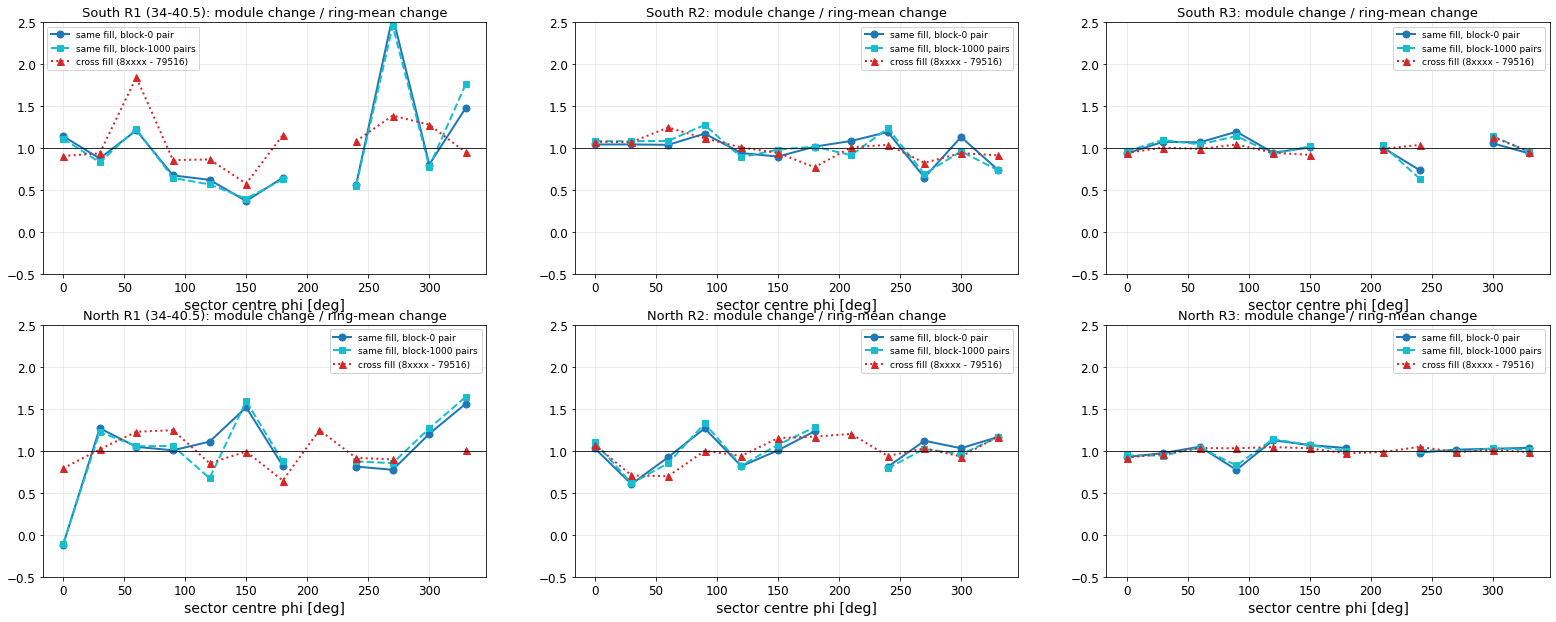

In [11]:
show(gs.fig_module_ratio())

### 3b. The basis fit (all clusters and two-row clusters only), λ = 2 (pull toward g = 1), jackknife errors

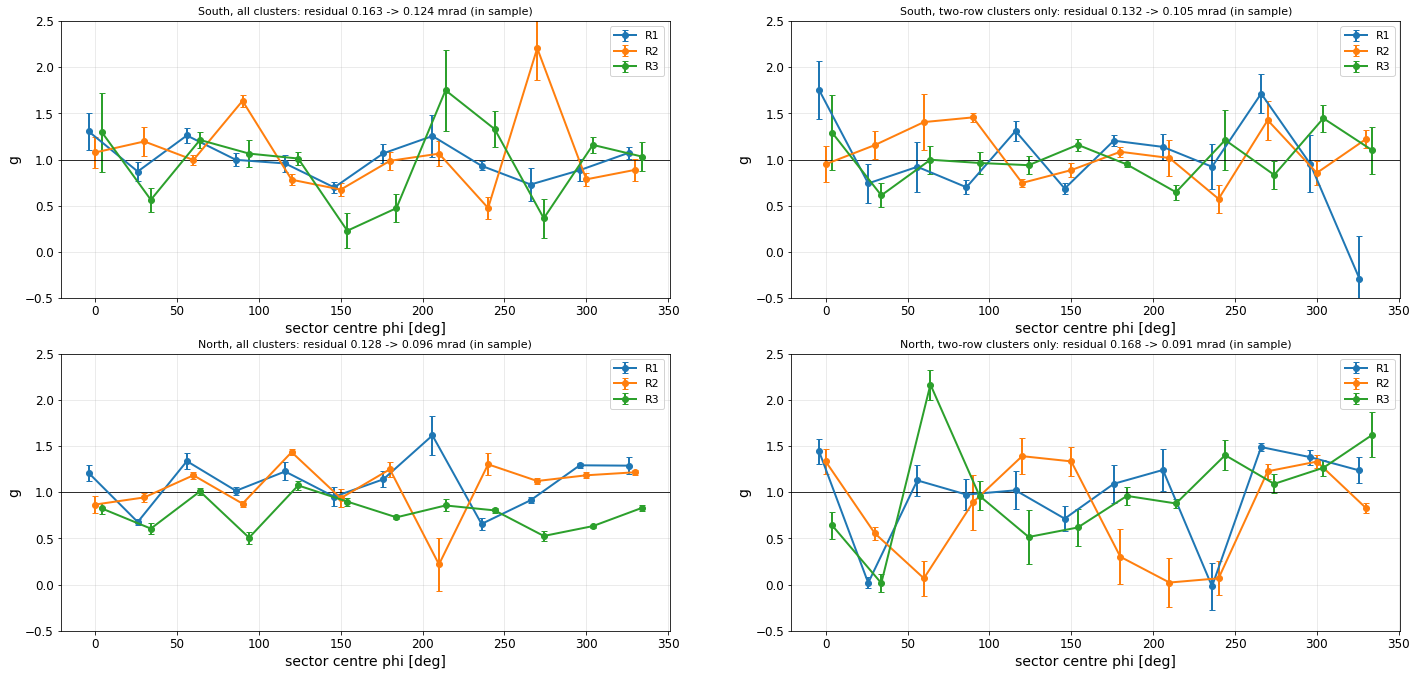

In [12]:
show(gs.fig_g(2.0))

### 3c. Do the fitted g predict a run left out of the fit? (residual per bin, mrad; the left-out run's own rotation allowed)

In [13]:
gs.oos_table()

South all     left out 79508: g = 1: fit 0.132 / left-out 0.261 | per ring: fit 0.130 / left-out 0.279 | per sector: fit 0.120 / left-out 0.260 | per module: fit 0.089 / left-out 0.333
South all     left out 79513: g = 1: fit 0.172 / left-out 0.178 | per ring: fit 0.167 / left-out 0.180 | per sector: fit 0.141 / left-out 0.187 | per module: fit 0.107 / left-out 0.178
South all     left out 79516: g = 1: fit 0.128 / left-out 0.262 | per ring: fit 0.122 / left-out 0.261 | per sector: fit 0.119 / left-out 0.247 | per module: fit 0.096 / left-out 0.244
North all     left out 79508: g = 1: fit 0.081 / left-out 0.225 | per ring: fit 0.078 / left-out 0.236 | per sector: fit 0.073 / left-out 0.230 | per module: fit 0.065 / left-out 0.247
North all     left out 79513: g = 1: fit 0.133 / left-out 0.134 | per ring: fit 0.118 / left-out 0.131 | per sector: fit 0.118 / left-out 0.132 | per module: fit 0.084 / left-out 0.130
North all     left out 79516: g = 1: fit 0.125 / left-out 0.166 | per ring:

- In sample every parametrisation improves the residual; out of sample none does consistently: the g fit the run-to-run
  variation of 1d, not a stable per-module gain.

## 4. Tracks (79513, CDB) vs the CM per sector

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/fixedset.py:74: RuntimeWarning: Mean of empty slice
  return {t: np.nanmean(D[t], axis=0) for t in tags}


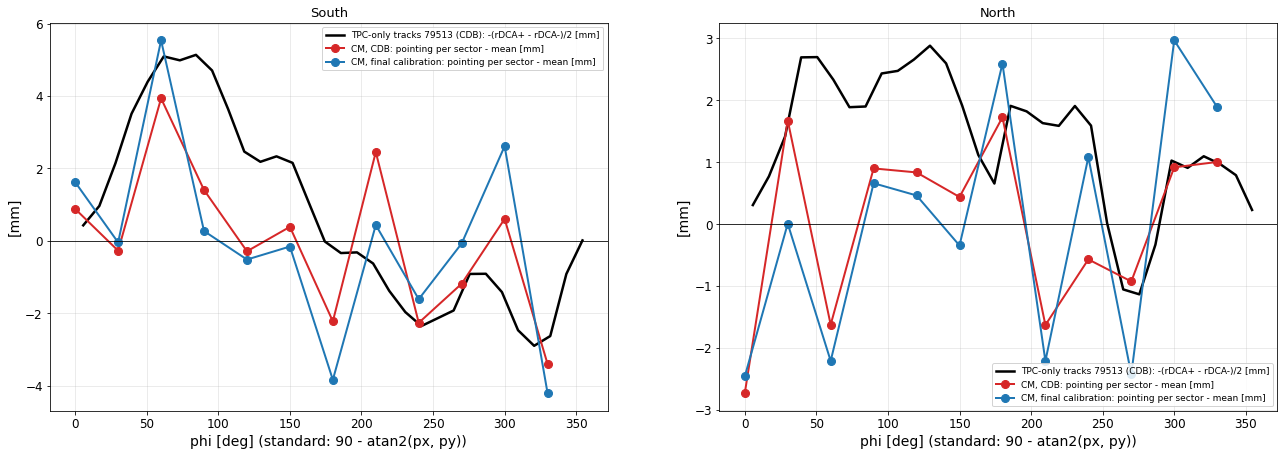

In [14]:
show(gs.fig_tracks_vs_cm())

### 4a. Track plots (TPC-only tracks, 79513)

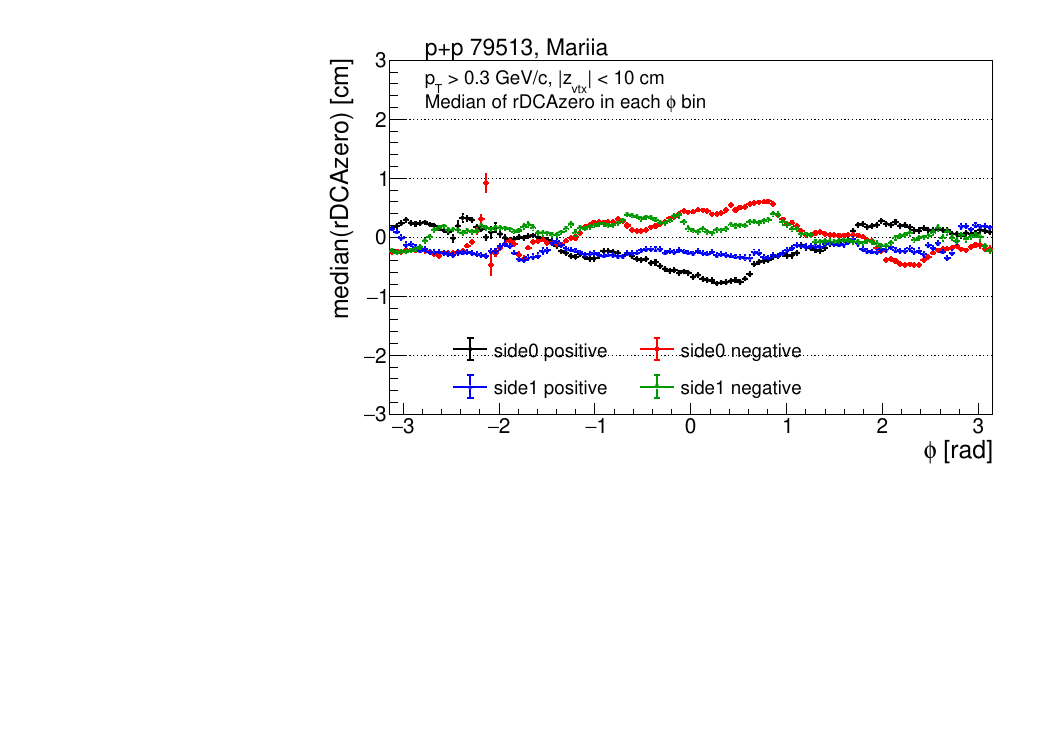

In [15]:
display(Image('track_figs/h_rDCAzero_vs_atan2_px_py_medians.png'))

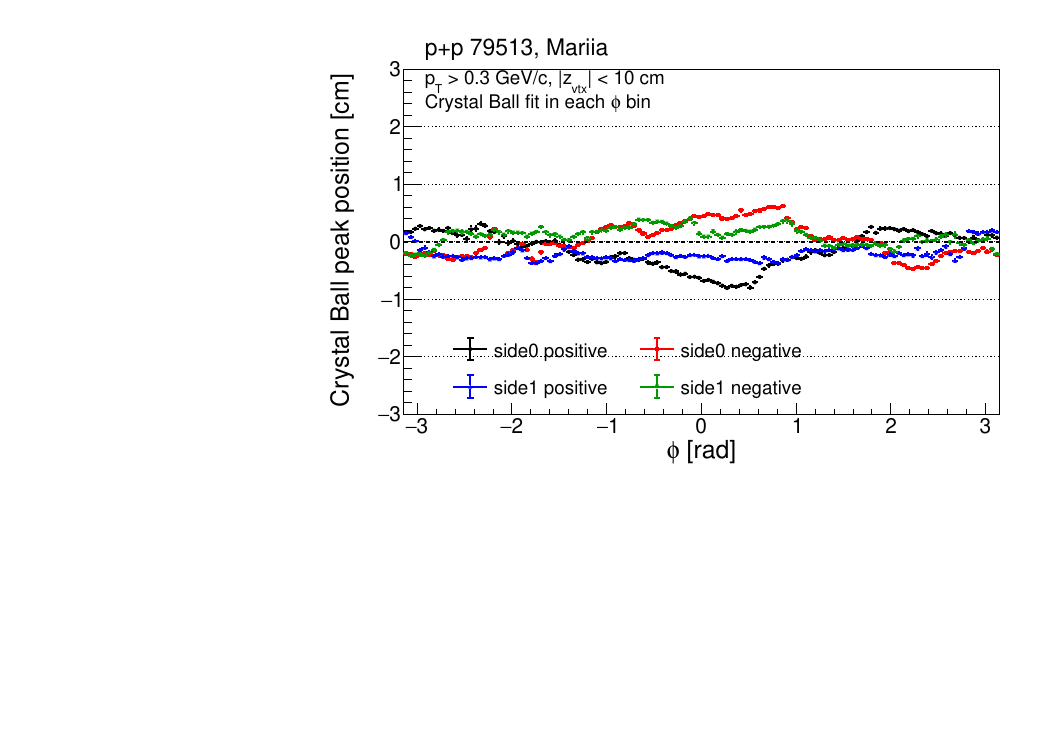

In [16]:
display(Image('track_figs/h_rDCAzero_vs_atan2_px_py_crystalball_peak.png'))

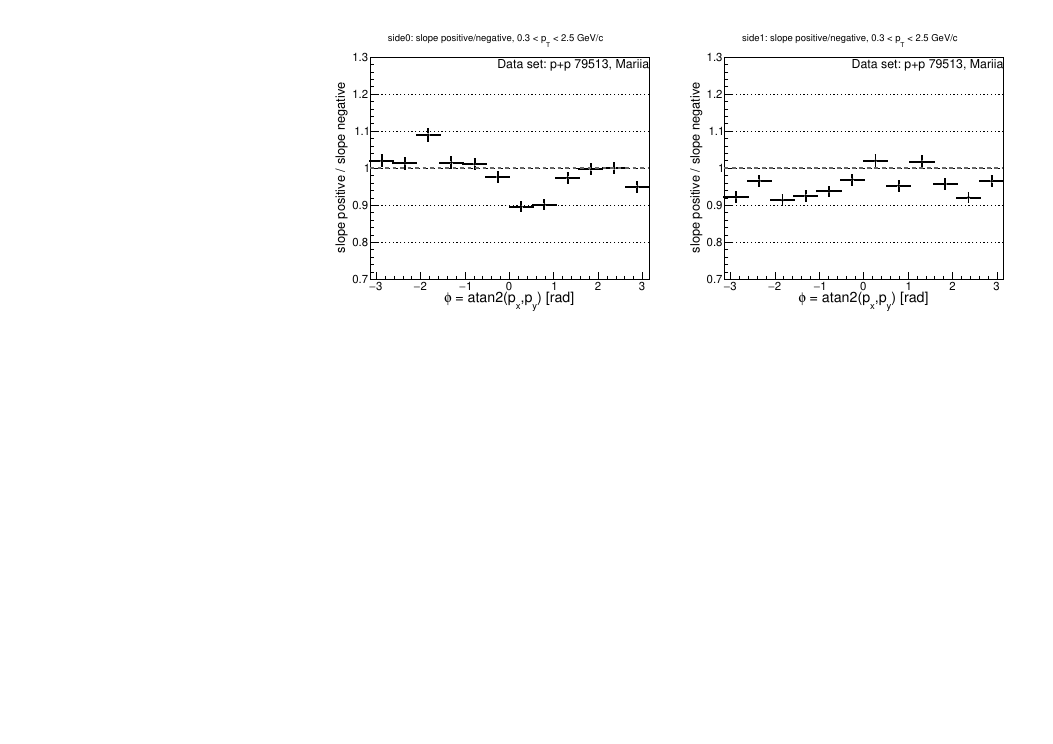

In [17]:
display(Image('track_figs/qa_pt_slope_ratio_phi_sides_full.png'))

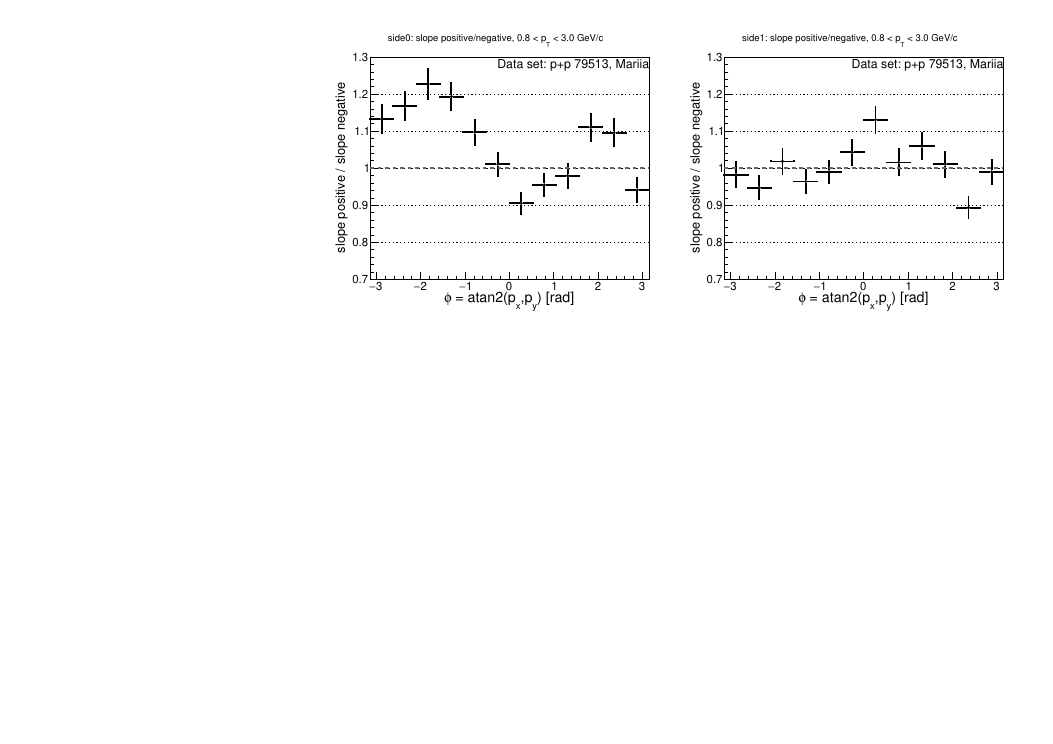

In [18]:
display(Image('track_figs/qa_pt_slope_ratio_phi_sides_high1.png'))

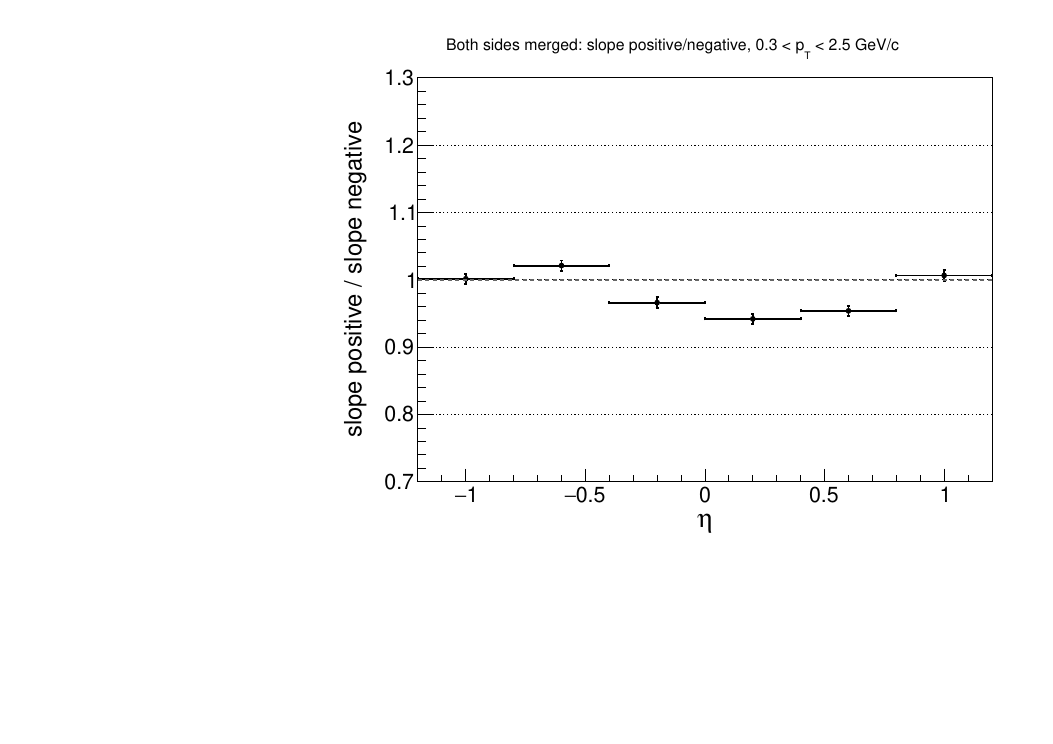

In [19]:
display(Image('track_figs/qa_pt_slope_ratio_eta_merged_full.png'))

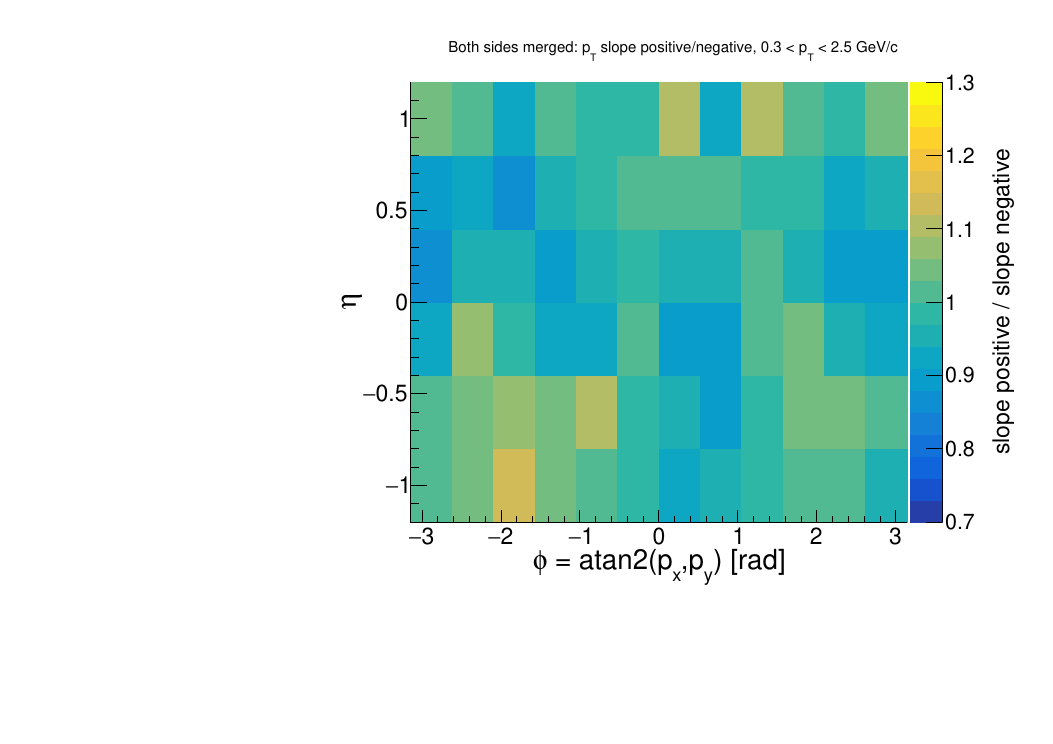

In [20]:
display(Image('track_figs/qa_pt_slope_ratio_phi_eta_merged_full.png'))

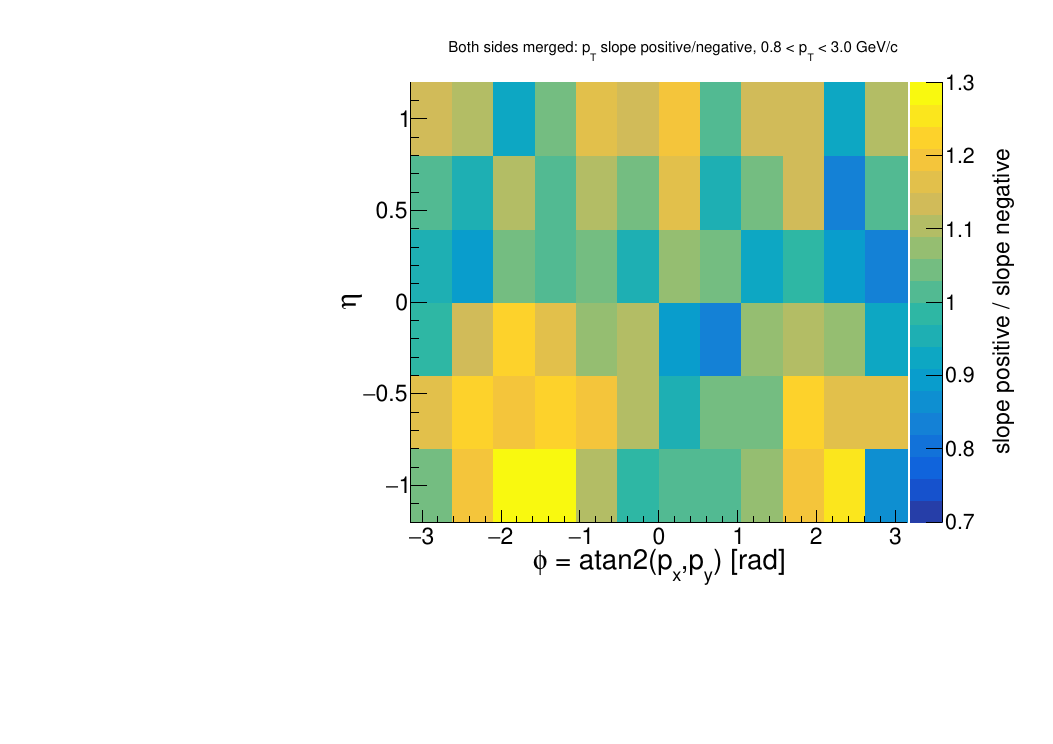

In [21]:
display(Image('track_figs/qa_pt_slope_ratio_phi_eta_merged_high1.png'))

**Reading the track plots in the CM frame**: φ_std = 90° − atan2(px, py). The South charge-odd rDCA dip and pT-slope ratio 0.90 at
atan2 = 0.3–0.9 rad are at φ_std ≈ 40–75° (CM sector 2); the ratio 1.09 at atan2 ≈ −1.8 rad is at φ_std ≈ 190° (sector 6).
The tracks see a stable pattern in these sectors – the per-module g from the CM have to reproduce it once the run-to-run
variation of Section 1 is understood.